# Battery Feature Lab: Zhang et al. EIS example

Screen every impedance spectrum recorded for one ageing coin cell, analyse a documented subset with Lin-KK consistency checks and equivalent-circuit fitting, compare later spectra with the first under explicit condition gates, and optionally ask GPT-5.6 Sol to interpret the saved JSON records.

Data: Zhang, Yunwei; Tang, Qiaochu; Zhang, Yao; Wang, Jiabin; Stimming, Ulrich; Lee, Alpha A. (2020), *Identifying degradation patterns of lithium ion batteries from impedance spectroscopy using machine learning*, Zenodo, [doi:10.5281/zenodo.3633835](https://doi.org/10.5281/zenodo.3633835), CC BY 4.0. Associated article: *Nature Communications* 11, 1706 (2020), [doi:10.1038/s41467-020-15235-7](https://doi.org/10.1038/s41467-020-15235-7).



## 1. Set up the example

Resolve repository-relative paths, verify the archive against the Zenodo checksum, and show the installed BFL and provider versions.

In [1]:
import contextlib
import hashlib
import importlib.metadata
import io
import json
import tempfile
import time
import zipfile
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import Markdown, display

import bfl

repo_root = Path.cwd().resolve()
while not (repo_root / "pyproject.toml").is_file() and repo_root.parent != repo_root:
    repo_root = repo_root.parent
data_path = Path("examples/data/Zhang_2020")
archive_path = repo_root / data_path / "EIS data.zip"
archive_member = "EIS data/EIS_state_V_25C01.txt"
output_path = Path("examples/outputs/Zhang_2020/EIS_state_V_25C01")
if not archive_path.is_file():
    raise FileNotFoundError(archive_path)
archive_md5 = hashlib.md5(archive_path.read_bytes()).hexdigest()
if archive_md5 != "9f31069d770d7d323d8e2bf21267afe2":
    raise ValueError(f"Archive does not match Zenodo record 3633835: {archive_md5}")

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "xtick.color": "#898781",
    "ytick.color": "#898781",
    "font.size": 9,
    "legend.frameon": False,
    "lines.linewidth": 2,
})
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
ORDINAL = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]
{
    "archive": (data_path / archive_path.name).as_posix(),
    "archive_md5": archive_md5,
    "member": archive_member,
    "output_directory": output_path.as_posix(),
    **{
        package: importlib.metadata.version(package)
        for package in (
            "battery-feature-lab",
            "battery-data-standard",
            "eisfit",
            "impedance",
            "numpy",
        )
    },
}

{'archive': 'examples/data/Zhang_2020/EIS data.zip',
 'archive_md5': '9f31069d770d7d323d8e2bf21267afe2',
 'member': 'EIS data/EIS_state_V_25C01.txt',
 'output_directory': 'examples/outputs/Zhang_2020/EIS_state_V_25C01',
 'battery-feature-lab': '0.5.0',
 'battery-data-standard': '0.3.1',
 'eisfit': '0.1.1',
 'impedance': '1.7.1',
 'numpy': '1.26.4'}

## 2. Inspect the source spectra

The authors report 45 mAh Eunicell LR2032 LiCoO₂/graphite coin cells cycled with a 1C (45 mA) CC–CV charge to 4.2 V and a 2C (90 mA) CC discharge to 3.0 V. Cells `25C01`–`25C08` were cycled in a 25 °C climate chamber. EIS was recorded from 20 kHz to 0.02 Hz with a 5 mA excitation at nine states of an EIS cycle. State V is the 15 min rest after full charge; the authors used it for their capacity and lifetime predictions.

Read cell `25C01`, state V, directly from the archive and check how the source identifies each sweep.

In [2]:
with zipfile.ZipFile(archive_path) as archive:
    source_bytes = archive.read(archive_member)
source_lines = source_bytes.decode("utf-8").splitlines()
source_header, source_rows = source_lines[0], [line for line in source_lines[1:] if line.strip()]
source_columns = [name.strip() for name in source_header.split("\t")]
source_values = np.array([[float(value) for value in row.split("\t")] for row in source_rows])
source_counter = source_values[:, source_columns.index("cycle number")].astype(int)
counters = sorted(set(source_counter.tolist()))
start_time_s = np.array([source_values[source_counter == c, 0].min() for c in counters])
{
    "member_sha256": hashlib.sha256(source_bytes).hexdigest(),
    "columns": source_columns,
    "rows": len(source_rows),
    "spectra": len(counters),
    "cycle_number_range": [counters[0], counters[-1]],
    "points_per_spectrum": sorted(set(Counter(source_counter.tolist()).values())),
    "frequency_range_hz": [float(source_values[:, 2].min()), float(source_values[:, 2].max())],
    "sweeps_are_contiguous": bool(np.all(np.diff(source_counter) >= 0)),
    "time_increases_monotonically": bool(np.all(np.diff(source_values[:, 0]) > 0)),
    "median_hours_between_sweeps": round(float(np.median(np.diff(start_time_s))) / 3600, 2),
}

{'member_sha256': '8c3d72efa52af2b28942a6c206befce50849d2c655ccc7ffd1f5be204634ed48',
 'columns': ['time/s',
  'cycle number',
  'freq/Hz',
  'Re(Z)/Ohm',
  '-Im(Z)/Ohm',
  '|Z|/Ohm',
  'Phase(Z)/deg'],
 'rows': 15660,
 'spectra': 261,
 'cycle_number_range': [1, 261],
 'points_per_spectrum': [60],
 'frequency_range_hz': [0.01999, 20004.453],
 'sweeps_are_contiguous': True,
 'time_increases_monotonically': True,
 'median_hours_between_sweeps': 3.95}

Each sweep carries a constant `cycle number` counter but no spectrum identifier recognised by BFL. Consecutive counters are about 3.9 h apart, and the authors report EIS on even-numbered cycles with capacity checks on odd-numbered cycles. The counter is therefore not assumed to equal the battery cycle number: it is declared as `sequence_index`, a recorded measurement order, rather than `cycle_index`.

## 3. Declare spectrum identity and measurement conditions

Write the source rows unchanged into a tab-delimited input table, prefixed with a `Spectrum_ID` built from the source counter. Every input table in this example is built this way, so each BFL row reference resolves to an unchanged source line.

Conditions are declared from the publication. The paper does not name the potentiostat. Because every sweep comes from one source file whose `time/s` column increases monotonically, the instrument is declared as one unnamed recording; section 8 shows how BFL gates the comparisons without that declaration.

In [3]:
spectrum_ids = {counter: f"25C01_V_{counter:03d}" for counter in counters}


def write_input_table(path, selected_counters):
    selected = set(selected_counters)
    lines = ["Spectrum_ID\t" + source_header]
    lines += [
        f"{spectrum_ids[counter]}\t{row}"
        for row, counter in zip(source_rows, source_counter.tolist(), strict=True)
        if counter in selected
    ]
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")
    return path


def declared_conditions(selected_counters, declare_instrument=True):
    defaults = {
        "cell_id": "25C01",
        "temperature_deg_c": 25.0,
        "soc_fraction": 1.0,
        "rest_time_s": 900.0,
        "ac_amplitude_a": 0.005,
        "protocol_id": "Zhang2020_state_V",
    }
    if declare_instrument:
        defaults["instrument"] = "unnamed_potentiostat_single_recording"
    return {
        "defaults": defaults,
        "spectra": {spectrum_ids[c]: {"sequence_index": c} for c in selected_counters},
    }


all_spectra_path = write_input_table(
    repo_root / data_path / "EIS_state_V_25C01_all.txt", counters
)
{
    "screening_table": all_spectra_path.relative_to(repo_root).as_posix(),
    "rows": len(all_spectra_path.read_text(encoding="utf-8").splitlines()) - 1,
    "spectrum_ids": [spectrum_ids[counters[0]], "...", spectrum_ids[counters[-1]]],
    "declared_defaults": declared_conditions(counters)["defaults"],
    "declared_per_spectrum": {spectrum_ids[counters[0]]: {"sequence_index": counters[0]}},
}

{'screening_table': 'examples/data/Zhang_2020/EIS_state_V_25C01_all.txt',
 'rows': 15660,
 'spectrum_ids': ['25C01_V_001', '...', '25C01_V_261'],
 'declared_defaults': {'cell_id': '25C01',
  'temperature_deg_c': 25.0,
  'soc_fraction': 1.0,
  'rest_time_s': 900.0,
  'ac_amplitude_a': 0.005,
  'protocol_id': 'Zhang2020_state_V',
  'instrument': 'unnamed_potentiostat_single_recording'},
 'declared_per_spectrum': {'25C01_V_001': {'sequence_index': 1}}}

## 4. Screen every spectrum

Run Lin-KK and fixed-frequency probes on all 261 sweeps without circuit fitting. The screening artifacts (about 11 MB) are written to a temporary directory. `impedance.py` prints Lin-KK iteration progress; that provider output is captured to keep the notebook readable.

In [4]:
probe_frequencies_hz = (0.1, 1.0, 10.0, 1000.0)


def records_by_counter(records, record_type):
    counter_of_uid = {
        r["attributes"]["spectrum_uid"]: int(
            r["attributes"]["conditions"]["sequence_index"]["value"]
        )
        for r in records
        if r["record_type"] == "operation.eis_conditions"
    }
    return {
        counter_of_uid[r["record_id"].split(":", 1)[1]]: r
        for r in records
        if r["record_type"] == record_type
    }


def residual_magnitude(kk_record):
    series = kk_record["series"]
    return np.maximum(np.abs(series["residual_real"]), np.abs(series["residual_imaginary"]))


provider_log = io.StringIO()
with tempfile.TemporaryDirectory() as screen_dir, contextlib.redirect_stdout(provider_log):
    started = time.perf_counter()
    screen = bfl.analyze_eis(
        all_spectra_path,
        output_dir=Path(screen_dir) / "screen",
        metadata=declared_conditions(counters),
        probe_frequencies_hz=probe_frequencies_hz,
        run_fit=False,
    )
    screen_seconds = time.perf_counter() - started
    screen_validation = json.loads(screen.analysis_validation_path.read_text(encoding="utf-8"))

screen_kk = records_by_counter(screen.records, "response.eis_kk")
screen_spectra = records_by_counter(screen.records, "response.eis_spectrum")
max_residual = np.array(
    [screen_kk[c]["metrics"]["maximum_normalized_residual"]["value"] for c in counters]
)
worst_frequency_hz = [
    screen_kk[c]["series"]["frequency_hz"][int(np.argmax(residual_magnitude(screen_kk[c])))]
    for c in counters
]
z_real_1khz = np.array(
    [screen_spectra[c]["metrics"]["z_real_at_1000_hz"]["value"] for c in counters]
)
step_index = int(np.argmax(np.abs(np.diff(z_real_1khz))))
{
    "elapsed_s": round(screen_seconds, 1),
    "validation_status": screen_validation["status"],
    "row_accounting": screen_validation["row_accounting"],
    "provider_calls": dict(
        Counter(f"{c['method']}:{c['status']}" for c in screen_validation["provider_calls"])
    ),
    "lin_kk_within_0.05": f"{int((max_residual <= 0.05).sum())}/{len(counters)}",
    "max_residual_range": [round(float(x), 4) for x in (max_residual.min(), max_residual.max())],
    "frequency_of_largest_residual_hz": dict(Counter(round(f, 3) for f in worst_frequency_hz)),
    "largest_change_in_z_real_at_1000_hz": {
        "between_counters": [counters[step_index], counters[step_index + 1]],
        "delta_ohm": round(float(np.diff(z_real_1khz)[step_index]), 4),
        "hours_between_sweeps": round(float(np.diff(start_time_s)[step_index]) / 3600, 2),
    },
    "captured_provider_stdout_lines": len(provider_log.getvalue().splitlines()),
}

{'elapsed_s': 24.1,
 'validation_status': 'warning',
 'row_accounting': {'accounted': True,
  'excluded_rows': 0,
  'input_rows': 15660,
  'retained_rows': 15660},
 'provider_calls': {'kk:ok': 261, 'ecm:not_invoked': 261},
 'lin_kk_within_0.05': '90/261',
 'max_residual_range': [0.0342, 0.072],
 'frequency_of_largest_residual_hz': {0.02: 261},
 'largest_change_in_z_real_at_1000_hz': {'between_counters': [16, 17],
  'delta_ohm': -0.085,
  'hours_between_sweeps': 4.25},
 'captured_provider_stdout_lines': 0}

Check whether the Lin-KK exceedance is confined to the 0.02 Hz point. Two separate questions are tested: within BFL's Lin-KK fit, do the other 59 points stay within the limit; and does Lin-KK pass when it is re-run without the 0.02 Hz point? The re-run calls `impedance.validation.linKK` directly with the settings recorded in BFL's evidence; it is a sensitivity check computed here, not a BFL metric.

In [5]:
from impedance.validation import linKK

kk_settings = {
    key: screen_kk[counters[0]]["method"]["parameters"][key]
    for key in ("c", "max_M", "fit_type", "add_cap")
}
same_fit_without_lowest, rerun_without_lowest, rerun_worst_frequency_hz = [], [], []
with contextlib.redirect_stdout(io.StringIO()):
    for c in counters:
        series = screen_spectra[c]["series"]
        f = np.asarray(series["frequency_hz"])
        z = np.asarray(series["zreal_ohm"]) + 1j * np.asarray(series["zimag_ohm"])
        lowest = f == f.min()
        same_fit_without_lowest.append(residual_magnitude(screen_kk[c])[~lowest].max())
        _, _, _, residual_real, residual_imag = linKK(f[~lowest], z[~lowest], **kk_settings)
        rerun = np.maximum(np.abs(residual_real), np.abs(residual_imag))
        rerun_without_lowest.append(rerun.max())
        rerun_worst_frequency_hz.append(float(f[~lowest][np.argmax(rerun)]))
same_fit_without_lowest = np.array(same_fit_without_lowest)
rerun_without_lowest = np.array(rerun_without_lowest)
{
    "lin_kk_settings_from_bfl_evidence": kk_settings,
    "bfl_all_60_points_within_0.05": f"{int((max_residual <= 0.05).sum())}/{len(counters)}",
    "same_fit_other_59_points_within_0.05": (
        f"{int((same_fit_without_lowest <= 0.05).sum())}/{len(counters)}"
    ),
    "same_fit_other_59_points_max": round(float(same_fit_without_lowest.max()), 4),
    "rerun_on_59_points_within_0.05": (
        f"{int((rerun_without_lowest <= 0.05).sum())}/{len(counters)}"
    ),
    "rerun_on_59_points_median": round(float(np.median(rerun_without_lowest)), 4),
    "rerun_frequency_of_largest_residual_hz": dict(
        Counter(round(f, 4) for f in rerun_worst_frequency_hz)
    ),
}

{'lin_kk_settings_from_bfl_evidence': {'c': 0.85,
  'max_M': 50,
  'fit_type': 'complex',
  'add_cap': False},
 'bfl_all_60_points_within_0.05': '90/261',
 'same_fit_other_59_points_within_0.05': '261/261',
 'same_fit_other_59_points_max': 0.0395,
 'rerun_on_59_points_within_0.05': '115/261',
 'rerun_on_59_points_median': 0.0502,
 'rerun_frequency_of_largest_residual_hz': {0.0253: 261}}

Every sweep is retained and accounted for. Two findings shape the detailed analysis:

- **Lin-KK.** 90 of 261 sweeps stay within the configured 0.05 limit. In every sweep the largest residual is at the final 0.02 Hz point, and within the same Lin-KK fit the other 59 points stay below 0.04. The point cannot simply be dropped: re-running Lin-KK without it brings only 115 sweeps within the limit, because the largest residual moves to the new lowest frequency. The exceedance is concentrated at the low-frequency end of the sweep; whether it reflects drift during the slowest measurements or a Lin-KK edge effect is not established here. BFL records the exceedance and keeps the residual limit as a configurable policy; it does not remove points.
- **A step change.** The real impedance drops abruptly by about 0.09 Ω at 1 kHz between counters 16 and 17, at every probe frequency, with no gap in `time/s`. The authors report that all cells completed 30 cycles at 25 °C before the chamber temperatures were changed; the source records no fixture or condition change. A condition gate built from declared metadata cannot detect an offset like this, so the detailed analysis uses a baseline after the step and its settling: six sweeps evenly spaced from counter 21 to the final sweep.

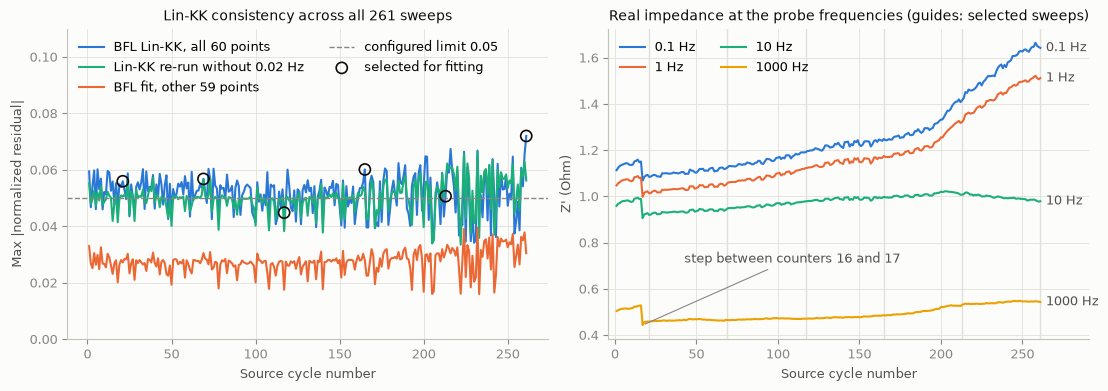

In [6]:
selected_counters = list(range(21, counters[-1] + 1, 48))
if not (counters[step_index + 1] < selected_counters[0] and selected_counters[-1] == counters[-1]):
    raise ValueError("The selected baseline must follow the step change and end at the last sweep")
selected_index = [counters.index(c) for c in selected_counters]
fig, (ax_kk, ax_probe) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")

ax_kk.plot(counters, max_residual, color=CATEGORICAL[0], linewidth=1.5,
           label="BFL Lin-KK, all 60 points")
ax_kk.plot(counters, rerun_without_lowest, color=CATEGORICAL[2], linewidth=1.5,
           label="Lin-KK re-run without 0.02 Hz")
ax_kk.plot(counters, same_fit_without_lowest, color=CATEGORICAL[1], linewidth=1.5,
           label="BFL fit, other 59 points")
ax_kk.axhline(0.05, color="#898781", linestyle="--", linewidth=1, label="configured limit 0.05")
ax_kk.scatter(selected_counters, max_residual[selected_index], s=64, facecolors="none",
              edgecolors="#0b0b0b", linewidths=1.2, zorder=3, label="selected for fitting")
ax_kk.set(title="Lin-KK consistency across all 261 sweeps", xlabel="Source cycle number",
          ylabel="Max |normalized residual|", ylim=(0, 0.11))
ax_kk.legend(loc="upper left", ncols=2)

for color, frequency in zip(CATEGORICAL, probe_frequencies_hz, strict=True):
    key = f"z_real_at_{frequency:.15g}_hz"
    values = [screen_spectra[c]["metrics"][key]["value"] for c in counters]
    ax_probe.plot(counters, values, color=color, linewidth=1.5, label=f"{frequency:g} Hz")
    ax_probe.annotate(f"{frequency:g} Hz", (counters[-1], values[-1]), xytext=(4, 0),
                      textcoords="offset points", va="center", color="#52514e")
for c in selected_counters:
    ax_probe.axvline(c, color="#e1e0d9", linewidth=1, zorder=0)
ax_probe.annotate(
    f"step between counters {counters[step_index]} and {counters[step_index + 1]}",
    (counters[step_index + 1], z_real_1khz[step_index + 1]), xytext=(30, 45),
    textcoords="offset points", color="#52514e",
    arrowprops={"arrowstyle": "-", "color": "#898781", "linewidth": 0.8},
)
ax_probe.set(title="Real impedance at the probe frequencies (guides: selected sweeps)",
             xlabel="Source cycle number", ylabel="Z' (Ohm)",
             xlim=(counters[0] - 5, counters[-1] + 30))
ax_probe.legend(loc="upper left", ncols=2)
plt.show()

## 5. Analyse the selected spectra with BFL

Write the six selected sweeps into their own input table, fit the two-arc equivalent circuit with 20 seeded multistarts, and compare each later spectrum with the first under the `ageing` gate. BFL requires an empty output directory, so artifacts from a previous run of this notebook are removed by name first.

In [7]:
input_path = write_input_table(
    repo_root / data_path / "EIS_state_V_25C01_selected.txt", selected_counters
)
conditions = declared_conditions(selected_counters)
comparison_pairs = tuple(
    (spectrum_ids[selected_counters[0]], spectrum_ids[c]) for c in selected_counters[1:]
)
output_dir = repo_root / output_path
artifact_names = (
    "normalized_eis.parquet",
    "eis_conversion_report.json",
    "analysis_metadata.json",
    "analysis_results.json",
    "analysis_evidence.json",
    "analysis_validation.json",
)
for name in artifact_names:
    (output_dir / name).unlink(missing_ok=True)

provider_log = io.StringIO()
with contextlib.redirect_stdout(provider_log):
    started = time.perf_counter()
    result = bfl.analyze_eis(
        input_path,
        output_dir=output_dir,
        metadata=conditions,
        probe_frequencies_hz=probe_frequencies_hz,
        fit_options={"tail": "cpe", "n_starts": 20, "seed": 7},
        comparison_pairs=comparison_pairs,
        comparison_kind="ageing",
    )
    analysis_seconds = time.perf_counter() - started
{
    "input_table": input_path.relative_to(repo_root).as_posix(),
    "input_sha256": hashlib.sha256(input_path.read_bytes()).hexdigest(),
    "selected_spectra": [spectrum_ids[c] for c in selected_counters],
    "comparison_pairs": comparison_pairs,
    "elapsed_s": round(analysis_seconds, 1),
    "files": [path.name for path in result.files],
}

{'input_table': 'examples/data/Zhang_2020/EIS_state_V_25C01_selected.txt',
 'input_sha256': 'edfc35bce37658b935c290b91edb10226e9395bceb2642ee65faded69b45957a',
 'selected_spectra': ['25C01_V_021',
  '25C01_V_069',
  '25C01_V_117',
  '25C01_V_165',
  '25C01_V_213',
  '25C01_V_261'],
 'comparison_pairs': (('25C01_V_021', '25C01_V_069'),
  ('25C01_V_021', '25C01_V_117'),
  ('25C01_V_021', '25C01_V_165'),
  ('25C01_V_021', '25C01_V_213'),
  ('25C01_V_021', '25C01_V_261')),
 'elapsed_s': 38.3,
 'files': ['normalized_eis.parquet',
  'eis_conversion_report.json',
  'analysis_metadata.json',
  'analysis_results.json',
  'analysis_evidence.json',
  'analysis_validation.json']}

## 6. Inspect the compact analysis result

Use the compact JSON as the discovery index: validation, row accounting, provider calls and one row per spectrum.

In [8]:
analysis = json.loads(result.analysis_results_path.read_text(encoding="utf-8"))
metadata = json.loads(result.analysis_metadata_path.read_text(encoding="utf-8"))
validation = json.loads(result.analysis_validation_path.read_text(encoding="utf-8"))
compact = [item for items in analysis["dimensions"].values() for item in items]
compact_by_id = {item["record_id"]: item for item in compact}
uid_of = {
    int(s["conditions"]["sequence_index"]["value"]): s["spectrum_uid"] for s in metadata["spectra"]
}
comparison_ids = {
    c: f"evolution.eis_comparison:{uid_of[selected_counters[0]]}:{uid_of[c]}"
    for c in selected_counters[1:]
}
{
    "validation_status": validation["status"],
    "row_accounting": validation["row_accounting"],
    "output_sizes_bytes": {path.name: path.stat().st_size for path in result.files},
    "record_type_counts": analysis["retrieval"]["record_type_counts"],
    "provider_calls": dict(
        Counter(f"{c['method']}:{c['status']}" for c in validation["provider_calls"])
    ),
    "software_versions": validation["software_versions"],
    "comparisons": {
        f"{spectrum_ids[selected_counters[0]]} -> {spectrum_ids[c]}": {
            "status": compact_by_id[record_id]["attributes"]["comparison_status"],
            "ecm_parameter_comparison": compact_by_id[record_id]["attributes"][
                "ecm_parameter_comparison_status"
            ],
            "quality_flags": compact_by_id[record_id]["quality"]["flags"],
        }
        for c, record_id in comparison_ids.items()
    },
}

{'validation_status': 'warning',
 'row_accounting': {'accounted': True,
  'excluded_rows': 0,
  'input_rows': 360,
  'retained_rows': 360},
 'output_sizes_bytes': {'normalized_eis.parquet': 8808,
  'eis_conversion_report.json': 3716,
  'analysis_metadata.json': 12065,
  'analysis_results.json': 86696,
  'analysis_evidence.json': 330034,
  'analysis_validation.json': 5057},
 'record_type_counts': {'evolution.eis_comparison': 5,
  'operation.eis_conditions': 6,
  'response.eis_ecm': 6,
  'response.eis_kk': 6,
  'response.eis_spectrum': 6},
 'provider_calls': {'kk:ok': 6, 'ecm:ok': 6},
 'software_versions': {'battery-data-standard': '0.3.1',
  'battery-feature-lab': '0.5.0',
  'bfl_eis_source_sha256': 'cb68073dd7d29ce1ad9b60d141f8817c1f56011edc2901ecd84e2f5991944c0c',
  'eisfit': '0.1.1',
  'impedance': '1.7.1',
  'numpy': '1.26.4'},
 'comparisons': {'25C01_V_021 -> 25C01_V_069': {'status': 'comparable',
   'ecm_parameter_comparison': 'not_computable',
   'quality_flags': ['measurement_co

In [9]:
compact_kk = records_by_counter(compact, "response.eis_kk")
compact_ecm = records_by_counter(compact, "response.eis_ecm")
pl.DataFrame([
    {
        "spectrum_id": spectrum_ids[c],
        "sequence_index": c,
        "kk_max_residual": round(
            compact_kk[c]["metrics"]["maximum_normalized_residual"]["value"], 4
        ),
        "kk_consistency": compact_kk[c]["attributes"]["measurement_consistency"],
        "ecm_convergence": compact_ecm[c]["attributes"]["convergence"],
        "ecm_nrmse": round(compact_ecm[c]["metrics"]["nrmse"]["value"], 4),
        "R0_Ohm": round(compact_ecm[c]["metrics"]["R0_Ohm"]["value"], 4),
        "R1_Ohm": round(compact_ecm[c]["metrics"]["R1_Ohm"]["value"], 4),
        "R2_Ohm": round(compact_ecm[c]["metrics"]["R2_Ohm"]["value"], 4),
        "ecm_applicability": compact_ecm[c]["applicability"]["status"],
        "ecm_quality_flags": ", ".join(compact_ecm[c]["quality"]["flags"]),
    }
    for c in selected_counters
])

spectrum_id,sequence_index,kk_max_residual,kk_consistency,ecm_convergence,ecm_nrmse,R0_Ohm,R1_Ohm,R2_Ohm,ecm_applicability,ecm_quality_flags
str,i64,f64,str,str,f64,f64,f64,f64,str,str
"""25C01_V_021""",21,0.0559,"""outside_configured_residual_li…","""converged""",0.0037,0.306,0.4399,0.2701,"""partial""","""measurement_consistency_not_es…"
"""25C01_V_069""",69,0.0568,"""outside_configured_residual_li…","""converged""",0.0048,0.3189,0.4478,0.2968,"""partial""","""measurement_consistency_not_es…"
"""25C01_V_117""",117,0.0448,"""within_configured_residual_lim…","""converged""",0.0075,0.3287,0.4761,0.3271,"""applicable""",""""""
"""25C01_V_165""",165,0.0601,"""outside_configured_residual_li…","""converged""",0.0065,0.3377,0.5001,0.3533,"""partial""","""measurement_consistency_not_es…"
"""25C01_V_213""",213,0.0507,"""outside_configured_residual_li…","""converged""",0.0092,0.3826,0.5433,0.4262,"""partial""","""measurement_consistency_not_es…"
"""25C01_V_261""",261,0.072,"""outside_configured_residual_li…","""converged""",0.0116,0.3883,0.6456,0.5706,"""partial""","""measurement_consistency_not_es…"


## 7. Retrieve detailed evidence

Follow record identifiers from the compact result to the circuit-fit audit, the comparison gate and the retained series.

In [10]:
evidence = json.loads(result.analysis_evidence_path.read_text(encoding="utf-8"))
evidence_by_id = {record["record_id"]: record for record in evidence["records"]}
spectra = records_by_counter(evidence["records"], "response.eis_spectrum")
kk = records_by_counter(evidence["records"], "response.eis_kk")
ecm = records_by_counter(evidence["records"], "response.eis_ecm")
comparisons = {c: evidence_by_id[record_id] for c, record_id in comparison_ids.items()}
latest_fit = ecm[selected_counters[-1]]
diagnostics = latest_fit["attributes"]["diagnostics"]
costs = sorted(attempt["cost"] for attempt in diagnostics["attempts"])
latest_comparison = comparisons[selected_counters[-1]]
{
    "ecm_fit": {
        "record_id": latest_fit["record_id"],
        "source_interval": {
            **{k: v for k, v in latest_fit["source_intervals"][0].items() if k != "source_rows"},
            "source_row_count": len(latest_fit["source_intervals"][0]["source_rows"]),
        },
        "circuit": latest_fit["attributes"]["circuit"],
        "method": {
            key: latest_fit["method"][key] for key in ("name", "provider", "provider_version")
        },
        "multistart_cost": {
            "accepted_starts": diagnostics["accepted_start_count"],
            "best": costs[0],
            "median": costs[len(costs) // 2],
            "worst": costs[-1],
        },
        "bound_hits": diagnostics["bound_hits"],
        "identifiability": diagnostics["identifiability_status"],
        "quality": latest_fit["quality"],
    },
    "comparison": {
        "record_id": latest_comparison["record_id"],
        "status": latest_comparison["attributes"]["comparison_status"],
        "missing_conditions": latest_comparison["attributes"]["missing_conditions"],
        "mismatched_conditions": latest_comparison["attributes"]["mismatched_conditions"],
        "common_frequency_window_hz": latest_comparison["attributes"]["common_frequency_window_hz"],
        "observed_differences_ohm": {
            name: round(value["value"], 4) for name, value in latest_comparison["metrics"].items()
        },
        "ecm_parameter_comparison": latest_comparison["attributes"][
            "ecm_parameter_comparison_status"
        ],
        "interpretation_limits": latest_comparison["interpretation_limits"],
    },
}

{'ecm_fit': {'record_id': 'response.eis_ecm:26f1f5f128cdfcdf',
  'source_interval': {'row_index_basis': 'zero_based_BDS_parsed_table',
   'sheet': None,
   'source_file': 'EIS_state_V_25C01_selected.txt',
   'source_sha256': 'edfc35bce37658b935c290b91edb10226e9395bceb2642ee65faded69b45957a',
   'source_row_count': 60},
  'circuit': 'L + R0 + (R1 || CPE1) + (R2 || CPE2) + cpe',
  'method': {'name': 'two_arc_ecm_v1',
   'provider': 'eisfit',
   'provider_version': '0.1.1'},
  'multistart_cost': {'accepted_starts': 20,
   'best': 0.0014528126124063432,
   'median': 0.05019362547594816,
   'worst': 3.5909673203639167},
  'bound_hits': [],
  'identifiability': 'not_assessed',
  'quality': {'flags': ['measurement_consistency_not_established'],
   'status': 'warning'}},
 'comparison': {'record_id': 'evolution.eis_comparison:13263cb7c685a33c:26f1f5f128cdfcdf',
  'status': 'comparable',
  'missing_conditions': [],
  'mismatched_conditions': [],
  'common_frequency_window_hz': [0.01999, 20004.45

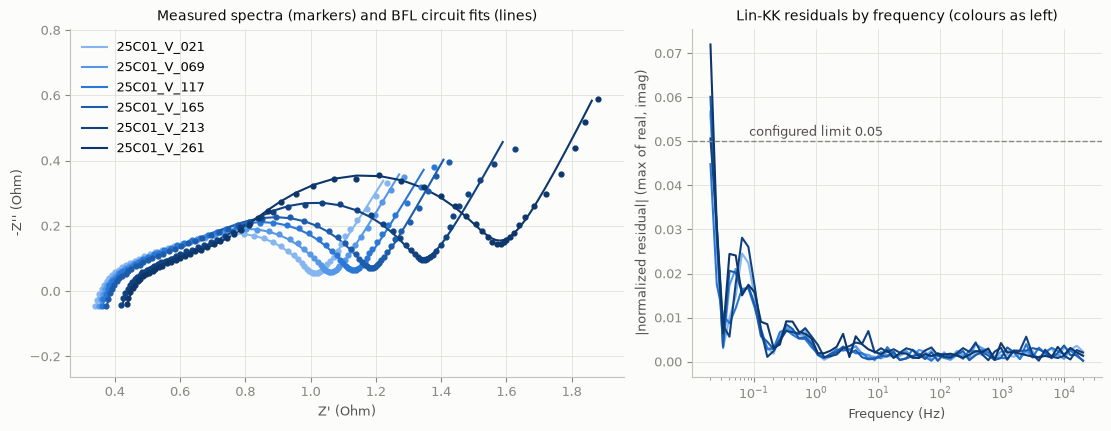

In [11]:
fig, (ax_nyquist, ax_residual) = plt.subplots(
    1, 2, figsize=(11, 4.2), layout="constrained", width_ratios=(1.35, 1)
)
for color, c in zip(ORDINAL, selected_counters, strict=True):
    measured, fitted = spectra[c]["series"], ecm[c]["series"]
    ax_nyquist.scatter(measured["zreal_ohm"], -np.asarray(measured["zimag_ohm"]), s=12,
                       color=color, zorder=3)
    ax_nyquist.plot(fitted["fitted_zreal_ohm"], -np.asarray(fitted["fitted_zimag_ohm"]),
                    color=color, linewidth=1.5, label=spectrum_ids[c])
    ax_residual.plot(kk[c]["series"]["frequency_hz"], residual_magnitude(kk[c]), color=color,
                     linewidth=1.5, label=spectrum_ids[c])
ax_nyquist.set(title="Measured spectra (markers) and BFL circuit fits (lines)",
               xlabel="Z' (Ohm)", ylabel="-Z'' (Ohm)")
ax_nyquist.set_aspect("equal", adjustable="datalim")
ax_nyquist.legend(loc="upper left")
ax_residual.axhline(0.05, color="#898781", linestyle="--", linewidth=1)
ax_residual.annotate("configured limit 0.05", (1.0, 0.05), xytext=(0, 4),
                     textcoords="offset points", ha="center", color="#52514e")
ax_residual.set(title="Lin-KK residuals by frequency (colours as left)", xscale="log",
                xlabel="Frequency (Hz)", ylabel="|normalized residual| (max of real, imag)")
plt.show()

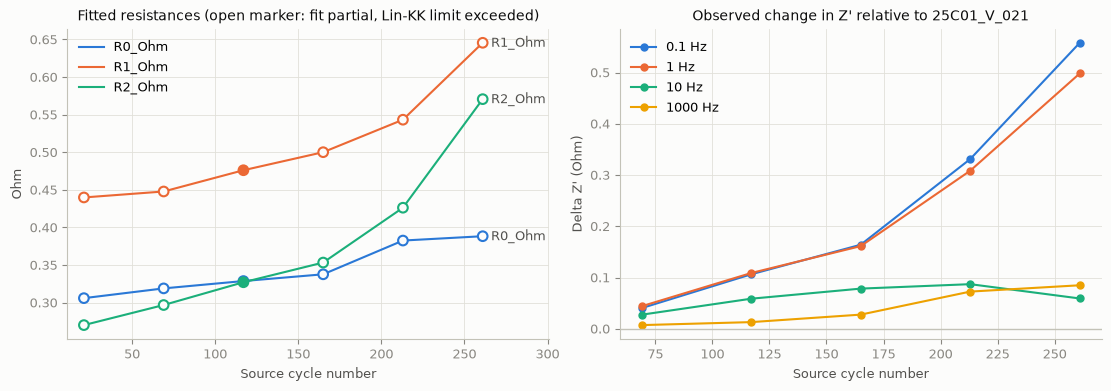

In [12]:
fig, (ax_ecm, ax_delta) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for color, name in zip(CATEGORICAL, ("R0_Ohm", "R1_Ohm", "R2_Ohm"), strict=False):
    values = [ecm[c]["metrics"][name]["value"] for c in selected_counters]
    applicable = [ecm[c]["applicability"]["status"] == "applicable" for c in selected_counters]
    ax_ecm.plot(selected_counters, values, color=color, linewidth=1.5, label=name)
    ax_ecm.scatter(selected_counters, values, s=48, zorder=3, edgecolors=color, linewidths=1.5,
                   facecolors=[color if ok else "#fcfcfb" for ok in applicable])
    ax_ecm.annotate(name, (selected_counters[-1], values[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", color="#52514e")
ax_ecm.set(title="Fitted resistances (open marker: fit partial, Lin-KK limit exceeded)",
           xlabel="Source cycle number", ylabel="Ohm",
           xlim=(selected_counters[0] - 10, selected_counters[-1] + 40))
ax_ecm.legend(loc="upper left")

for color, frequency in zip(CATEGORICAL, probe_frequencies_hz, strict=True):
    key = f"delta_z_real_at_{frequency:.15g}_hz"
    values = [comparisons[c]["metrics"][key]["value"] for c in selected_counters[1:]]
    ax_delta.plot(selected_counters[1:], values, color=color, linewidth=1.5, marker="o",
                  markersize=5, label=f"{frequency:g} Hz")
ax_delta.axhline(0, color="#c3c2b7", linewidth=1)
ax_delta.set(title=f"Observed change in Z' relative to {spectrum_ids[selected_counters[0]]}",
             xlabel="Source cycle number", ylabel="Delta Z' (Ohm)")
ax_delta.legend(loc="upper left")
plt.show()

Every pair passes the `ageing` condition gate, so BFL emits the observed impedance differences at the probe frequencies. Differences between circuit parameters need two `applicable` fits; the baseline fit is only `partial` because its Lin-KK check exceeds the limit, so BFL withholds every parameter difference (`not_computable`) and the resistance panel shows each fit separately. Arc numbering follows characteristic time and does not establish a persistent physical process, so these are fitted values, not mechanisms.

## 8. Check the comparison gate

Re-run the comparison step without circuit fitting: once with the declared conditions, once without the instrument declaration, and once with the pair order reversed.

In [13]:
def gate(conditions_, pair):
    with tempfile.TemporaryDirectory() as gate_dir:
        checked = bfl.analyze_eis(
            input_path,
            output_dir=Path(gate_dir) / "gate",
            metadata=conditions_,
            probe_frequencies_hz=probe_frequencies_hz,
            run_kk=False,
            run_fit=False,
            comparison_pairs=(pair,),
            comparison_kind="ageing",
        )
    record = next(r for r in checked.records if r["record_type"] == "evolution.eis_comparison")
    return {
        "pair": pair,
        "status": record["attributes"]["comparison_status"],
        "missing_conditions": record["attributes"]["missing_conditions"],
        "mismatched_conditions": record["attributes"]["mismatched_conditions"],
        "observed_differences_emitted": len(record["metrics"]),
    }


latest_pair = comparison_pairs[-1]
{
    "declared_conditions": gate(conditions, latest_pair),
    "instrument_not_declared": gate(
        declared_conditions(selected_counters, declare_instrument=False), latest_pair
    ),
    "pair_order_reversed": gate(conditions, latest_pair[::-1]),
}

{'declared_conditions': {'pair': ('25C01_V_021', '25C01_V_261'),
  'status': 'comparable',
  'missing_conditions': [],
  'mismatched_conditions': [],
  'observed_differences_emitted': 8},
 'instrument_not_declared': {'pair': ('25C01_V_021', '25C01_V_261'),
  'status': 'conditional',
  'missing_conditions': ['instrument'],
  'mismatched_conditions': [],
  'observed_differences_emitted': 0},
 'pair_order_reversed': {'pair': ('25C01_V_261', '25C01_V_021'),
  'status': 'incompatible',
  'missing_conditions': [],
  'mismatched_conditions': ['recorded_ageing_order'],
  'observed_differences_emitted': 0}}

## 9. Prepare the controlled AI inputs

Keep the first three conditions as original files and configure one shared GPT-5.6 Sol prompt with light (`low`) reasoning effort and no token-length setting.

In [14]:
import os
from getpass import getpass

from openai import OpenAI

intake_json_path = result.input_report_path
intake_bfl_json_paths = (
    result.input_report_path,
    result.analysis_metadata_path,
    result.analysis_results_path,
    result.analysis_evidence_path,
    result.analysis_validation_path,
)

prompt = """
You are a battery engineer.

Analyse the supplied battery data and explain:
1. what the battery experienced,
2. how it responded,
3. how it evolved.

"""

if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass("OpenAI API key: ")
client = OpenAI()
response_settings = {
    "model": "gpt-5.6-sol",
    "reasoning": {"effort": "low"},
    "text": {"verbosity": "medium"},
    "store": False,
}


def upload_original_files(paths):
    uploaded = []
    for path in paths:
        with path.open("rb") as source:
            uploaded.append(client.files.create(file=source, purpose="user_data"))
    return uploaded


def original_file_condition(uploaded_files):
    return [
        {
            "role": "user",
            "content": [
                *[{"type": "input_file", "file_id": item.id} for item in uploaded_files],
                {"type": "input_text", "text": prompt},
            ],
        }
    ]


def delete_uploaded_files(uploaded_files):
    for item in uploaded_files:
        client.files.delete(item.id)


def usage(response):
    return {
        "model": response.model,
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens,
    }


{
    "raw_input": input_path.relative_to(repo_root).as_posix(),
    "intake_only": [intake_json_path.name],
    "intake_bfl": [path.name for path in intake_bfl_json_paths],
}

{'raw_input': 'examples/data/Zhang_2020/EIS_state_V_25C01_selected.txt',
 'intake_only': ['eis_conversion_report.json'],
 'intake_bfl': ['eis_conversion_report.json',
  'analysis_metadata.json',
  'analysis_results.json',
  'analysis_evidence.json',
  'analysis_validation.json']}

## 10. Experiment 1 — raw measurements

Upload the six-sweep input table: the unchanged source rows plus the `Spectrum_ID` column. The temporary Files API object is deleted after the response.

In [15]:
uploaded_raw_files = upload_original_files((input_path,))
try:
    raw_response = client.responses.create(
        **response_settings,
        input=original_file_condition(uploaded_raw_files),
    )
finally:
    delete_uploaded_files(uploaded_raw_files)
display(usage(raw_response))
display(Markdown(raw_response.output_text))

{'model': 'gpt-5.6-sol', 'input_tokens': 18021, 'output_tokens': 2807}

## Executive assessment

These are electrochemical impedance spectroscopy (EIS) measurements at 25 °C, taken from cycle 21 to cycle 261 over approximately 39 days between the first and last spectra. The battery shows clear, progressive impedance growth, followed by accelerated degradation after roughly cycles 165–213.

The main changes are:

- increasing high-frequency/ohmic resistance,
- substantial growth of the mid-frequency polarization arc,
- a shift of the dominant relaxation to lower frequency,
- increasingly strong low-frequency transport polarization.

Together, these indicate that the cell became both more resistive and kinetically slower with cycling.

---

## 1. What the battery experienced

### Repeated operation and periodic impedance measurements

The spectra were recorded at cycles:

- 21
- 69
- 117
- 165
- 213
- 261

The test identifier suggests a nominal 25 °C condition. The nearly regular cycle spacing indicates repeated cycling or another recurring duty profile, with EIS characterization approximately every 48 cycles.

The absolute timestamps correspond to approximately:

| Cycle | Test time |
|---:|---:|
| 21 | 3.73 days |
| 69 | 12.09 days |
| 117 | 20.25 days |
| 165 | 28.12 days |
| 213 | 35.83 days |
| 261 | 42.92 days |

The cycling rate appears to have increased slightly toward the end, although this cannot be confirmed without the underlying current/voltage history.

### Progressive electrochemical aging

The cell experienced cumulative aging rather than a single catastrophic failure. However, the degradation rate was not constant:

- **Cycles 21–165:** relatively gradual impedance growth.
- **Cycles 165–213:** a noticeable transition, particularly in high-frequency resistance and mid-frequency behavior.
- **Cycles 213–261:** strong growth of the polarization arc and low-frequency impedance.

This suggests a change from relatively mild aging to a more severe degradation regime.

---

## 2. How the battery responded

### A. Ohmic resistance increased

The high-frequency real-axis intercept can be estimated near the point where `-Im(Z)` crosses zero, around 10–12.5 kHz.

| Cycle | Approx. high-frequency resistance |
|---:|---:|
| 21 | ~0.357 Ω |
| 69 | ~0.368 Ω |
| 117 | ~0.376 Ω |
| 165 | ~0.388 Ω |
| 213 | ~0.436 Ω |
| 261 | ~0.449 Ω |

This is an increase of approximately **26% from cycle 21 to cycle 261**.

The large step between cycles 165 and 213 is important. High-frequency resistance can contain contributions from:

- electrolyte ionic resistance,
- current collectors and tabs,
- electrode/contact resistance,
- separator/electrolyte wetting,
- interfacial films with very fast time constants.

At constant temperature, the sustained increase is most consistent with aging-related resistance growth rather than a simple temperature effect.

The negative values of `-Im(Z)` at the highest frequencies indicate a small inductive response. This is commonly caused by leads, fixtures, tabs, or instrument compensation and is not, by itself, evidence of abnormal cell electrochemistry.

---

### B. Polarization resistance grew substantially

At representative frequencies, the real impedance increased as follows:

| Frequency | Cycle 21 | Cycle 261 | Increase |
|---:|---:|---:|---:|
| 10 kHz | 0.360 Ω | 0.456 Ω | ~27% |
| 10–11 Hz | 0.910 Ω | 0.955 Ω | ~5% |
| 1.07 Hz | 1.012 Ω | 1.506 Ω | ~49% |
| 0.53 Hz | 1.027 Ω | 1.557 Ω | ~52% |
| 0.020 Hz | 1.235 Ω | 1.882 Ω | ~52% |

The modest change around 10 Hz hides a major change in spectral shape: the dominant arc progressively moved through this frequency region. At frequencies below about 2 Hz, polarization became much larger.

The increasing separation between the high-frequency intercept and the lower-frequency real impedance indicates growth in the combined interfacial and charge-transfer resistance.

---

### C. The electrochemical processes became slower

The peak of the main capacitive response moved systematically to lower frequency:

| Cycle | Approx. peak frequency | Peak `-Im(Z)` | Approx. time constant \(1/(2\pi f)\) |
|---:|---:|---:|---:|
| 21 | ~28–36 Hz | ~0.176 Ω | ~4–6 ms |
| 69 | ~28 Hz | ~0.191 Ω | ~5.6 ms |
| 117 | ~18 Hz | ~0.209 Ω | ~8.9 ms |
| 165 | ~14 Hz | ~0.226 Ω | ~11 ms |
| 213 | ~9 Hz | ~0.269 Ω | ~18 ms |
| 261 | ~4–7 Hz | ~0.35 Ω | ~23–36 ms |

Thus, the characteristic response time increased by roughly a factor of **six to eight**.

This means that charge transfer and/or interfacial ion transport became progressively slower. The simultaneous increase in peak height indicates that this was not just a frequency shift—the associated resistance also grew.

Likely contributors include:

- thickening of surface films such as the SEI,
- loss of active electrode area,
- poorer electronic contact within porous electrodes,
- reduced electrolyte access or pore transport,
- increased charge-transfer resistance.

The data alone cannot uniquely separate these mechanisms.

---

### D. Low-frequency transport polarization increased

At 0.020 Hz:

- `-Im(Z)` increased from **0.332 Ω** at cycle 21 to **0.589 Ω** at cycle 261, about a **77% increase**.
- \(|Z|\) increased from **1.279 Ω** to **1.972 Ω**, about a **54% increase**.
- The phase became more negative overall, from approximately **−15.1°** to **−17.4°**.

This indicates increasingly important slow processes, such as:

- solid-state lithium diffusion,
- electrolyte transport through porous electrodes,
- concentration polarization,
- non-uniform reaction distribution through electrode thickness.

The low-frequency region does not form a clean ideal 45° Warburg line, so it likely contains overlapping diffusion, porous-electrode, and finite-length effects.

---

## 3. How the battery evolved

### Stage 1: Gradual aging — cycles 21 to 165

During this period:

- high-frequency resistance rose slowly from about 0.357 to 0.388 Ω,
- the arc peak increased from about 0.176 to 0.226 Ω,
- the peak shifted from roughly 30–36 Hz toward 14 Hz,
- low-frequency impedance increased moderately.

This is consistent with normal cumulative cycling degradation: gradual film growth, active-area loss, and increasing charge-transfer resistance.

There is no clear indication of a sudden internal short or abrupt open-circuit failure.

---

### Stage 2: Transition to stronger degradation — cycles 165 to 213

This interval shows a distinct change:

- high-frequency resistance jumped from approximately 0.388 to 0.436 Ω,
- the main arc shifted further down to around 9 Hz,
- the arc became broader and larger,
- low-frequency real impedance increased significantly.

This may mark the onset of an additional aging mechanism or a threshold being crossed. Plausible causes include:

- accelerated SEI or cathode-interphase growth,
- electrolyte depletion or redistribution,
- contact degradation,
- electrode cracking or loss of active material,
- pore blockage or increasing transport heterogeneity.

Because the EIS was not accompanied by capacity, DC resistance, SOC, or temperature history, the exact mechanism cannot be identified uniquely.

---

### Stage 3: Accelerated polarization growth — cycles 213 to 261

The final interval exhibits the strongest kinetic deterioration:

- the main peak moves to approximately 4–7 Hz,
- peak `-Im(Z)` rises to around 0.35 Ω,
- real impedance around 1 Hz rises from 1.319 to 1.506 Ω,
- impedance at 0.020 Hz rises from 1.683 to 1.972 Ω,
- the low-frequency phase becomes more negative.

At cycle 261, the spectrum contains a pronounced broad mid-frequency arc and stronger low-frequency tail. This means the cell is increasingly limited by both:

1. **interfacial reaction kinetics**, and  
2. **mass transport/concentration polarization**.

The result in service would likely be:

- larger voltage drop under load,
- reduced power capability,
- more heat generation at a given current,
- earlier arrival at charge/discharge voltage limits,
- reduced usable capacity at moderate or high rate,
- poorer fast-charge acceptance.

---

## Overall conclusion

The battery underwent progressive cycling-induced aging at 25 °C. It initially degraded gradually, but after approximately cycle 165 the impedance growth accelerated.

By cycle 261:

- high-frequency resistance was about **26% higher**,
- low-frequency impedance magnitude was about **54% higher**,
- the dominant electrochemical time constant was roughly **6–8 times longer**,
- the capacitive/polarization response had become much larger,
- diffusion and concentration-polarization effects were more pronounced.

The cell had not experienced an obvious abrupt catastrophic event, but it had entered a substantially more resistive and slower electrochemical state. The most likely interpretation is combined interphase growth, increased charge-transfer resistance, loss of effective reaction area, and worsening transport within the electrodes. Capacity and DC pulse data would be required to determine whether this impedance growth was accompanied primarily by loss of lithium inventory, loss of active material, or contact/electrolyte degradation.

## 11. Experiment 2 — BDS-backed intake report only

Upload only the unchanged EIS intake report to test what column mapping, sign handling and row accounting can support without the measurements.

In [16]:
uploaded_intake_files = upload_original_files((intake_json_path,))
try:
    intake_only_response = client.responses.create(
        **response_settings,
        input=original_file_condition(uploaded_intake_files),
    )
finally:
    delete_uploaded_files(uploaded_intake_files)
display(usage(intake_only_response))
display(Markdown(intake_only_response.output_text))

{'model': 'gpt-5.6-sol', 'input_tokens': 1121, 'output_tokens': 704}

## Assessment

The supplied information is an **EIS ingestion/validation summary**, not the impedance measurements themselves. It confirms that the dataset is structurally sound, but it does not include the frequency, impedance, time, or cycle-number values needed for electrochemical interpretation.

### 1. What the battery experienced

What can be established:

- The battery underwent **six electrochemical impedance spectroscopy measurements**.
- Each spectrum contains **60 frequency points**, for **360 total observations**.
- The measurements can potentially be ordered by:
  - elapsed time (`time/s`), and
  - cycle number (`cycle number`).
- No points were excluded, and all six spectra passed the Battery Data Standard validation.
- The source stored the imaginary component as **−Im(Z)**. This was recognized and sign-corrected during intake.

What cannot be established from this summary:

- The frequency range and perturbation amplitude.
- State of charge, temperature, current history, rest time, or cycling conditions.
- Whether the battery experienced charging, discharging, calendar aging, cycling aging, heating, or an abuse event.

### 2. How the battery responded

Each spectrum contains the required quantities to evaluate the response:

- real impedance, \(Z'\),
- imaginary impedance, \(Z''\),
- impedance magnitude, \(|Z|\),
- derived phase angle.

However, the numerical values are absent here. Therefore, it is not possible to determine:

- series/ohmic resistance,
- charge-transfer or interfacial resistance,
- semicircle size or depression,
- characteristic relaxation frequencies,
- diffusion/Warburg behavior,
- low-frequency polarization,
- inductive features,
- or whether any spectrum indicates abnormal degradation.

The data validation result—**valid, no issues**—only means the format and required fields are acceptable. It does **not** mean the battery was electrochemically healthy.

### 3. How it evolved

There are six snapshots, so evolution could be assessed by ordering spectra by time or cycle number and comparing:

1. the high-frequency real-axis intercept,
2. the diameter and position of impedance arcs,
3. phase-angle peaks and their characteristic frequencies,
4. the low-frequency slope and impedance,
5. fitted equivalent-circuit parameters across measurements.

But because neither the impedance values nor the mapping between spectrum IDs and time/cycle is supplied, no defensible trend can be stated. In particular, one cannot conclude whether resistance increased, kinetics slowed, diffusion worsened, or the cell remained stable.

## Overall conclusion

The only supported conclusion is that the battery was measured by EIS on **six occasions**, producing six complete, valid 60-point spectra. The supplied metadata is insufficient to explain the battery’s operating history, electrochemical response, or degradation trajectory.

A quantitative engineering analysis requires the 360-row table containing at least:

`Spectrum_ID`, `Frequency_Hz`, `Zre_exp_Ohm`, `Zim_exp_Ohm`, `time/s`, and `cycle number`,

plus, ideally, temperature and state of charge.

## 12. Experiment 3 — intake report + BFL JSON

Upload the unchanged intake report together with every BFL JSON artifact as the complete machine-readable condition.

In [17]:
uploaded_intake_bfl_files = upload_original_files(intake_bfl_json_paths)
try:
    intake_bfl_response = client.responses.create(
        **response_settings,
        input=original_file_condition(uploaded_intake_bfl_files),
    )
finally:
    delete_uploaded_files(uploaded_intake_bfl_files)
display(usage(intake_bfl_response))
display(Markdown(intake_bfl_response.output_text))

{'model': 'gpt-5.6-sol', 'input_tokens': 124284, 'output_tokens': 1620}

## Overall assessment

Cell **25C01** underwent repeated EIS measurements at six protocol sequence points—**21, 69, 117, 165, 213, and 261**—under nominally constant reported conditions. Its impedance progressively increased, especially at low frequencies, indicating a substantial deterioration in measured electrical response over the sequence. The data demonstrate impedance growth, but do **not** by themselves establish a specific degradation mechanism or prove that ageing was the cause.

## 1. What the battery experienced

- Cell: **25C01**
- Protocol: **Zhang2020_state_V**
- Temperature: **25 °C**
- Reported SOC: **100%**
- Rest before measurement: **900 s**
- AC current amplitude: **5 mA**
- EIS range: **0.01999 Hz to 20.004 kHz**
- Six spectra, each containing **60 valid points**
- No points were excluded and no duplicate frequencies were found.

The changing variable was the **sequence index**. Actual cycle count, elapsed ageing time, DC voltage, and voltage perturbation amplitude were not reported. Consequently, the sequence indices should not be interpreted directly as cycle numbers or elapsed time.

## 2. How the battery responded

### Direct impedance response

All spectra were numerically valid and covered the same frequency range. The response showed:

- A small inductive contribution at the highest frequencies.
- Depressed mid-frequency impedance arcs.
- An increasingly prominent low-frequency tail.
- A general rightward and downward shift in the complex-impedance representation, corresponding to higher real impedance and more negative imaginary impedance.

Selected measured values illustrate the change from sequence 21 to 261:

| Frequency | Sequence 21 | Sequence 261 | Change |
|---|---:|---:|---:|
| \(Z'\), 1000 Hz | 0.458 Ω | 0.543 Ω | **+0.085 Ω** |
| \(Z'\), 10 Hz | 0.920 Ω | 0.979 Ω | **+0.059 Ω** |
| \(Z'\), 1 Hz | 1.013 Ω | 1.512 Ω | **+0.498 Ω** |
| \(Z'\), 0.1 Hz | 1.085 Ω | 1.643 Ω | **+0.558 Ω** |
| \(Z''\), 10 Hz | −0.131 Ω | −0.309 Ω | **−0.178 Ω** |
| \(Z''\), 1 Hz | −0.055 Ω | −0.198 Ω | **−0.143 Ω** |
| \(Z''\), 0.1 Hz | −0.125 Ω | −0.205 Ω | **−0.080 Ω** |

Thus, the largest growth occurred at **low frequencies**, while the high-frequency change was smaller. This means the later spectra show much greater slow-timescale polarization than the initial spectrum.

The overall maximum impedance modulus increased from approximately **1.279 Ω to 1.972 Ω**, an increase of about **54%**.

### Equivalent-circuit response

The circuit

\[
L + R_0 + (R_1 \parallel \mathrm{CPE}_1)
+ (R_2 \parallel \mathrm{CPE}_2) + \mathrm{CPE}_{tail}
\]

converged for every spectrum and reproduced the data with low errors. NRMSE ranged from **0.0037 to 0.0116**, well below the configured 0.05 limit.

From sequence 21 to 261:

- \(R_0\): **0.306 → 0.388 Ω**, about **+27%**
- \(R_1\): **0.440 → 0.646 Ω**, about **+47%**
- \(R_2\): **0.270 → 0.571 Ω**, about **+111%**
- \(R_1+R_2\): **0.710 → 1.216 Ω**, about **+71%**

These fits are consistent with growth in both the high-frequency/series contribution and the modeled polarization contributions. However, parameter identifiability, uncertainty, and stability were not assessed. In addition, arc numbering is based on characteristic-time ordering; it does not prove that “R1” and “R2” represent the same physical processes in every spectrum.

## 3. How the battery evolved

### Progressive impedance growth

Relative to sequence 21, low-frequency real impedance increased approximately as follows:

| Sequence | Δ\(Z'\) at 1 Hz | Δ\(Z'\) at 0.1 Hz |
|---:|---:|---:|
| 69 | +0.044 Ω | +0.040 Ω |
| 117 | +0.109 Ω | +0.106 Ω |
| 165 | +0.161 Ω | +0.164 Ω |
| 213 | +0.308 Ω | +0.331 Ω |
| 261 | +0.498 Ω | +0.558 Ω |

The evolution was therefore not merely a fixed horizontal offset. The divergence became much larger toward low frequency, showing increasing frequency-dependent polarization.

There appear to be two broad stages:

1. **Sequences 21–165:** relatively gradual impedance growth.
2. **Sequences 165–261:** accelerated low-frequency growth, particularly after sequence 213.

At 10 Hz, the real impedance rose through sequence 213 and then decreased slightly at sequence 261, while the imaginary component continued becoming more negative. This suggests that the spectral shape was changing, not simply scaling uniformly.

### Data-quality qualification

Lin-KK testing found:

- Sequence **117** was within the configured residual limit.
- The other five spectra each had **one of 60 points** above the 0.05 limit.
- The largest residual always occurred at the lowest measured frequency, **0.01999 Hz**.
- Maximum normalized residual ranged from about **0.045 to 0.072**.

The deviations are limited to the low-frequency boundary, but they mean measurement consistency is not fully established for most spectra. Possible contributors include low-frequency drift, insufficient stationarity, or truncation of a process extending below the measured frequency window. For that reason, the strongest conclusions should come from the directly observed spectral trend rather than detailed circuit-parameter attribution.

## Engineering conclusion

The battery experienced repeated measurements at fixed reported temperature, SOC, rest period, and excitation amplitude while progressing through the protocol sequence. Its response evolved toward:

- higher high-frequency/series resistance,
- substantially higher mid- and low-frequency polarization,
- stronger low-frequency imaginary response,
- and a larger overall impedance magnitude.

The measured evolution is consistent with a significant loss of electrical performance and increasing resistance to both fast and slow electrochemical response. It is especially pronounced at low frequency and accelerates late in the sequence. Nevertheless, because cycle count, elapsed time, DC voltage, and independent degradation evidence are absent—and because most spectra have a minor low-frequency Lin-KK warning—the data support **impedance growth under the recorded conditions**, not a unique ageing mechanism or causal diagnosis.

## 13. Experiment 4 — BFL-guided evidence retrieval

Resolve every compact-result identifier in the evidence file and send the retrieved records without their dense arrays. Measured spectra, fitted spectra and residual series remain in `analysis_evidence.json`; each retrieved record keeps its source interval, method, diagnostics, quality and interpretation limits.

In [18]:
retrieved_condition = {
    result.input_report_path.name: json.loads(
        result.input_report_path.read_text(encoding="utf-8")
    ),
    result.analysis_metadata_path.name: metadata,
    result.analysis_results_path.name: analysis,
    "retrieved_evidence_records": [
        {key: value for key, value in evidence_by_id[item["record_id"]].items() if key != "series"}
        for item in compact
    ],
    result.analysis_validation_path.name: validation,
}
retrieval_response = client.responses.create(
    **response_settings,
    input=[
        {
            "role": "user",
            "content": [
                {"type": "input_text", "text": prompt},
                {
                    "type": "input_text",
                    "text": json.dumps(retrieved_condition, ensure_ascii=False),
                },
            ],
        }
    ],
)
display(usage(retrieval_response))
display(Markdown(retrieval_response.output_text))

{'model': 'gpt-5.6-sol', 'input_tokens': 68257, 'output_tokens': 1821}

## Executive assessment

Cell **25C01 experienced progressive ageing between repeated EIS checks**, and its impedance increased substantially—especially at low frequencies and during the later part of the sequence. This indicates worsening power capability and increasing electrochemical polarization. The data support degradation of several internal processes, but do **not** uniquely identify a chemical failure mechanism.

## 1. What the battery experienced

The cell was measured six times at sequence indices:

**21, 69, 117, 165, 213 and 261**

Each EIS measurement was performed under nominally matched conditions:

- **100% SOC**
- **25 °C**
- **900 s rest**
- **5 mA AC excitation**
- **0.01999 Hz to 20.0 kHz**
- 60 valid points per spectrum, with no exclusions or duplicate frequencies

The comparisons are therefore suitable for tracking ageing-related change under the recorded conditions.

However, the intervening duty history is not included: cycle number, elapsed time, DC voltage and the operations between measurements are unreported. Consequently, the data establish that the cell changed as the sequence progressed, but not whether this resulted from cycling, calendar ageing, high-voltage exposure, or a combination.

## 2. How the battery responded

### Initial response

At sequence 21, the cell already had appreciable impedance:

- \(Z'\) at 1 kHz: **0.458 Ω**
- \(Z'\) at 10 Hz: **0.920 Ω**
- \(Z'\) at 1 Hz: **1.013 Ω**
- \(Z'\) at 0.1 Hz: **1.085 Ω**
- Maximum impedance magnitude: **1.279 Ω**

The response contained:

- A high-frequency inductive contribution, likely dominated by leads and cell construction.
- Multiple distributed interfacial time constants.
- A pronounced low-frequency polarization/transport response.

The equivalent-circuit representation fitted the spectra well numerically. For the initial spectrum it gave approximately:

- Series resistance \(R_0\): **0.306 Ω**
- Distributed resistive terms \(R_1\): **0.440 Ω**, \(R_2\): **0.270 Ω**
- NRMSE: **0.0037**

These fitted elements should be treated as mathematical descriptors rather than uniquely assigned to SEI, charge transfer, cathode or anode processes.

### Final response

By sequence 261, the response was substantially more resistive and more strongly polarized:

- \(Z'\) at 1 kHz: **0.543 Ω**
- \(Z'\) at 1 Hz: **1.512 Ω**
- \(Z'\) at 0.1 Hz: **1.643 Ω**
- Maximum impedance magnitude: **1.972 Ω**

Relative to sequence 21:

| Indicator | Initial | Final | Change |
|---|---:|---:|---:|
| \(Z'\), 1 kHz | 0.458 Ω | 0.543 Ω | **+0.085 Ω / +19%** |
| \(Z'\), 10 Hz | 0.920 Ω | 0.979 Ω | **+0.059 Ω / +6%** |
| \(Z'\), 1 Hz | 1.013 Ω | 1.512 Ω | **+0.498 Ω / +49%** |
| \(Z'\), 0.1 Hz | 1.085 Ω | 1.643 Ω | **+0.558 Ω / +51%** |
| Maximum \(|Z|\) | 1.279 Ω | 1.972 Ω | **+54%** |

The imaginary impedance also became substantially more negative at low and intermediate frequencies—for example, at 1 Hz it changed from **−0.055 Ω to −0.198 Ω**. Under the reported \(Z''\) convention, this signifies a larger capacitive/polarization response and a modified distribution of electrochemical time constants.

In practical terms, the aged battery would be expected to show:

- Greater voltage sag under load
- Greater overpotential during charging
- Lower pulse-power capability
- More heat generation at a given current
- Slower apparent electrochemical response

Capacity loss cannot be quantified from EIS alone.

## 3. How it evolved

### Early and middle period: gradual impedance growth

From sequence 21 to 165, impedance increased fairly steadily:

- At 1 Hz: **+0.044, +0.109 and +0.161 Ω** by sequences 69, 117 and 165
- At 0.1 Hz: **+0.040, +0.106 and +0.164 Ω**
- At 1 kHz: only **+0.007 to +0.028 Ω**

This shows that early degradation was weighted more strongly toward interfacial and slower polarization processes than toward purely ohmic resistance.

### Late period: accelerated deterioration

The growth became much stronger after approximately sequence 165:

- At 1 Hz, the increase relative to the first measurement grew from **+0.161 Ω at sequence 165** to **+0.308 Ω at 213** and **+0.498 Ω at 261**.
- At 0.1 Hz, it grew from **+0.164 Ω** to **+0.331 Ω** and then **+0.558 Ω**.
- Maximum \(|Z|\) increased from **1.48 Ω at sequence 165** to **1.68 Ω at 213** and **1.97 Ω at 261**.

Thus, the evolution was **nonlinear**: moderate and progressive initially, followed by a clear late-life acceleration.

The circuit fits show the same broad trend:

- \(R_0\): **0.306 → 0.388 Ω** (**+27%**)
- \(R_1\): **0.440 → 0.646 Ω** (**+47%**)
- \(R_2\): **0.270 → 0.571 Ω** (**+111%**)

This suggests that both baseline conduction/contact resistance and distributed interfacial polarization increased, with the largest relative rise in the slower fitted resistive contribution. The changing CPE parameters also indicate increasing heterogeneity or a broader distribution of time constants. These assignments remain qualitative because model identifiability and persistent arc identity were not established.

## Engineering interpretation

The strongest evidence is for:

1. **A modest increase in high-frequency/ohmic resistance**
2. **A much larger increase in low-frequency polarization**
3. **Growth and reshaping of interfacial time constants**
4. **Late-stage acceleration of degradation**

This pattern is consistent with a combination of increasing film/contact resistance, deteriorating charge-transfer kinetics and worsening transport limitations. EIS alone cannot determine whether the root cause was SEI growth, electrolyte degradation, loss of active material, lithium inventory loss, pore blockage, contact loss, or another mechanism.

## Data-quality qualification

All 360 points were retained and the circuit fits converged with NRMSE below **1.2%**, so the overall trend is robust. Lin–KK testing nevertheless flagged one point—always the lowest-frequency point at **0.01999 Hz**—in five of the six spectra. The maximum normalized residual was approximately **5–7%**. This may reflect low-frequency drift or incomplete stationarity. It reduces confidence in detailed interpretation of the extreme low-frequency tail, but does not explain away the large, systematic impedance growth across the broader spectrum.

**Overall conclusion:** the battery underwent substantial and accelerating impedance-based ageing. Its internal resistance and polarization increased across the sequence, with slow/interfacial processes deteriorating more severely than the high-frequency ohmic contribution.